# CSS 布局

定位与装饰（前端第08天，CSS第06天）


本日接着盒子模型、浮动和学成在线首页，学习如何让小图标叠在卡片上、让二维码居中出现在导航下方，以及设置圆角、溢出、隐藏等细节效果。

资料依据：`day08.rar` 中的 `day08（CSS06-定位+装饰）v1.0.pdf`（共83页）、课堂案例、`CSS第06天（定位+装饰）总结.xmind`、三项必做案例和选做资料。资料分享：[第02～10天课程资料](https://pan.baidu.com/s/1Cf1WISQ8Fc15xm7gf0VyBw?pwd=1234)，提取码 `1234`。

学习顺序：

1. **定位**：静态、相对、绝对、子绝父相、居中、固定、层级。
2. **装饰**：垂直对齐、光标、圆角、溢出、显示隐藏，以及透明度、表格边框合并、三角形。
3. **选择器拓展**：链接伪类、焦点伪类、属性选择器。
4. **原课练习与复习**：三项必做、遮罩选做、两个项目练习及本日检查。

代码以原资料为依据，保留课堂代码中启用与注释的区别。代码块用于阅读：HTML 与 CSS 分开的案例，分别放在页面的 `<body>` 与 `<style>` 中；完整 HTML 可另存为 `.html` 文件，再配套放置原案例的 `images` 目录。笔记中的图片已嵌入，阅读图片不依赖资料文件夹。

**补充：** XMind 内部根标题残留了“CSS第05天”，按下载目录、PDF名称和XMind文件名，本笔记统一记为“前端第08天，CSS第06天”。


## 1. 定位

定位用于控制盒子的位置，尤其适合子元素叠在父元素上，以及把盒子固定在屏幕某个位置。理解每一种定位时，都要同时回答三个问题：**参照谁移动、是否占原来的位置、方位属性是否生效**。


### 1.1 标准流、浮动与定位分别做什么

| 布局方式 | 本课程中的主要用途 | 典型例子 |
| --- | --- | --- |
| 标准流 | 按标签原有显示模式依次排列 | 块盒子从上往下；行内内容在一行排列 |
| 浮动 | 让多个块盒子横向排列 | 导航项、学成在线课程卡片 |
| 定位 | 控制盒子的偏移和叠放位置 | 卡片右上角 hot 标记、图片底部遮罩、固定工具栏 |

卡片的横向排列仍可交给浮动；卡片上的 hot 小图则使用定位。两种方式可以配合，先完成主体排列，再补叠放细节。

**本日两个常见场景：** 子绝父相让子盒子贴着父盒子定位；固定定位让盒子在页面滚动时保持屏幕上的位置。


### 1.2 使用定位：方式加方位偏移

基本步骤：先设置 `position`，再按需要设置水平方向和垂直方向的偏移。

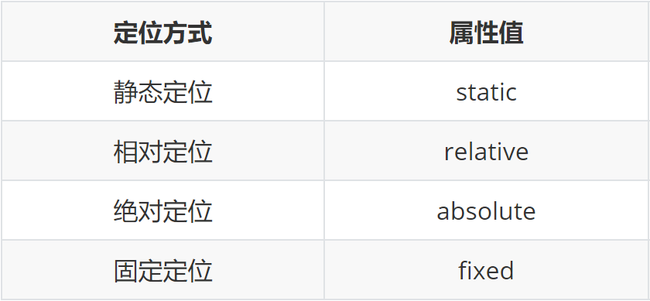

| 属性 | 含义 | 常见写法 |
| --- | --- | --- |
| `left` | 从左侧确定偏移 | `left: 20px;` |
| `right` | 从右侧确定偏移 | `right: 20px;` |
| `top` | 从顶部确定偏移 | `top: 10px;` |
| `bottom` | 从底部确定偏移 | `bottom: 10px;` |

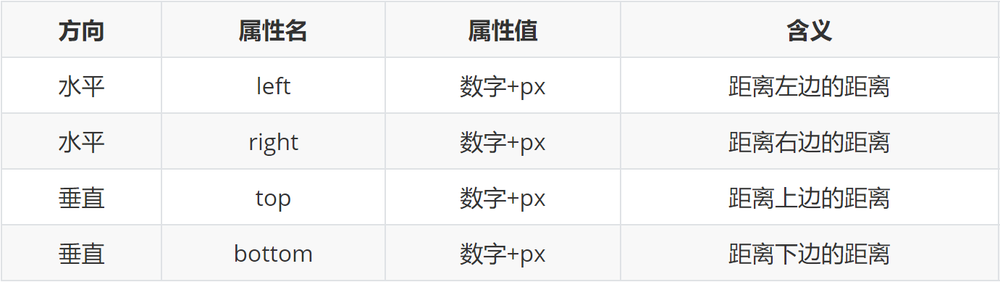

```css
.box {
    position: absolute;
    right: 20px;
    bottom: 10px;
}
```

本课通常水平方向选 `left` 或 `right`，垂直方向选 `top` 或 `bottom`，选距离目标位置近的一边更容易表达。偏移参照由定位方式决定，不能看到 `left` 就默认参照浏览器。

**补充：** 相对定位中的 `left: 20px` 表示在原位置基础上向右移20px，`right: 20px` 则向左移20px；绝对定位中的 `right: 20px` 表示盒子的右侧距定位参照区域右侧20px。两者不能混用同一种理解。


### 1.3 静态定位：默认状态

`position: static` 是默认值。本课将它理解为按标准流排布，不利用方位属性移动盒子。

课堂 `01-定位-静态.html` 的 CSS：

```css
/* css书写: 1. 定位 / 浮动 / display ; 2. 盒子模型; 3. 文字属性 */
.box {
    /* 静态定位, 默认值, 标准流 */
    position: static;
    left: 100px;
    top: 200px;

    width: 200px;
    height: 200px;
    background-color: pink;
}
```

页面中在一组段落之间放置了：

```html
<div class="box">box</div>
```

**观察结果：** 即使写了 `left: 100px` 和 `top: 200px`，粉色盒子也不会按这两个值偏移，仍在段落之间占据自己的位置。

课件之后说到“已定位的元素”时，主要指 `relative`、`absolute`、`fixed`，默认的 `static` 不算本课所说的定位参照。


### 1.4 相对定位：参照自己，保留占位

```css
position: relative;
```

三个特点：

1. 配合方位属性，移动盒子的显示位置。
2. 参照自己在正常排布中原来的位置。
3. **仍占原来的位置，没有脱标**；其他元素不会自动补到它原先的空位中。

应用：微调元素位置；为绝对定位的后代提供参照。只写 `position: relative`，不写方位偏移，父盒子本身可以保持原位置。

课堂 `02-定位-相对.html`：

```css
/* 如果left和right都有, 以left为准; top和bottom都有以top 为准 */
/* css书写: 1. 定位 / 浮动 / display ; 2. 盒子模型; 3. 文字属性 */
.box {
    position: relative;
    right: 200px;
    bottom: 400px;
    left: 100px;
    top: 200px;



    /* 
        1. 占有原来的位置
        2. 仍然具体标签原有的显示模式特点
        3. 改变位置参照自己原来的位置
    */

    width: 200px;
    height: 200px;
    background-color: pink;
}
```

**当前代码结果：** 在本例默认从左到右的文字方向下，水平方向同时写 `right` 和 `left` 时采用 `left: 100px`，垂直方向同时写 `bottom` 和 `top` 时采用 `top: 200px`。盒子向右100px、向下200px显示；原占位仍在。

**补充：** 源码注释中的“left优先”适用于本例的相对定位和默认文字方向，不要直接套到所有定位方式。练习时每个方向选一个方位属性即可。


### 1.5 绝对定位：脱标，向祖先找参照

```css
position: absolute;
```

绝对定位的盒子不再占据原来的标准流位置，后面的标准流内容会按它已离开来排布。它可以叠在其他盒子上，移动不需要把周围内容一起挤开。

本课中的参照查找顺序：

1. 从父元素向上查找祖先元素。
2. 找到最近的已定位祖先（本课主要是 `relative`、`absolute`、`fixed`），便以它为参照。
3. 祖先都未定位时，以初始包含块为参照。

课堂 `03-定位-绝对.html`：

```css
/* css书写: 1. 定位 / 浮动 / display ; 2. 盒子模型; 3. 文字属性 */
.box {
    /* 绝对定位: 
        先找已经定位的父级, 如果有这样的父级就以这个父级为参照物进行定位;
        有父级, 但父级没有定位, 以浏览器窗口为参照为进行定位
    */

    position: absolute;
    /* left: 50px; */
    left: 0;
    top: 0;


    /* 
    1. 脱标, 不占位
    2. 改变标签的显示模式特点: 具体行内块特点(在一行共存, 宽高生效)
    */

    width: 200px;
    height: 200px;
    background-color: pink;
}
```

HTML 仍是在段落之间写 `<div class="box">box</div>`，当前代码却让它显示在页面左上方，并且不再在原段落之间占位。

**补充：** 课件把没有定位祖先时的参照简称“浏览器”，更准确的是**初始包含块**。页面滚动时，这种绝对定位通常随文档一起滚动；它和固定定位贴住可视区域的效果不同。

**补充：** 源码用“具备行内块特点”解释宽高可设置、默认宽度常由内容决定。这是在类比部分行为，不表示实际变成了 `display: inline-block`。绝对定位的盒子脱离了普通排布；不能拿它当普通行内块横排。


### 1.6 子绝父相：让子元素跟着父元素

“子绝父相”就是子元素使用绝对定位、父元素使用相对定位。父元素留在正常布局中，子元素则参照父元素控制位置，适合卡片角标、二维码和遮罩。

```css
.father {
    position: relative;
}
.son {
    position: absolute;
    right: 0;
    top: 0;
}
```

课堂 `04-定位-绝对-父级定位.html` 用三层盒子说明“找最近的定位祖先”：

CSS（放在 `<style>` 内）：

```css
.father {
    position: relative;

    width: 400px;
    height: 400px;
    background-color: pink;
}

.son {
    /*  相对, 绝对 */
    /* 父级相对定位; 子级绝对定位 -- 子绝父相 */
    /* position: relative; */
    /* position: absolute; */
    /* right: 100px; */

    width: 300px;
    height: 300px;
    background-color: skyblue;
}

.sun {
    position: absolute;
    /* left: 20px;
    top: 30px; */
    right: 20px;
    bottom: 50px;

    width: 200px;
    height: 200px;
    background-color: green;
}

/* 绝对定位查找父级的方式: 就近找定位的父级, 如果逐层查找不到这样的父级, 就以浏览器窗口为参照进行定位 */
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
    <div class="son">
        <div class="sun"></div>
    </div>
</div>
```

**当前代码的参照：** `.sun` 是绝对定位，直接父级 `.son` 的定位声明都被注释，因此跳过 `.son`，找到 `.father` 的 `position: relative`。绿色盒子距粉色父盒子右侧20px、底部50px。

尝试取消 `.son` 的 `position: relative` 注释后，`.sun` 才会改为参照蓝色 `.son`。是否“最近”看祖先是否建立本课的定位参照，不能只看HTML中是否是直接父元素。

**原课拓展：子绝父绝。** 父盒子如果已经使用绝对定位，仍可成为子元素绝对定位的参照；不用为了口诀强行改为相对定位，因为修改父盒子的定位方式可能改变主体布局。


### 1.7 hot 角标：把新知识加到学成在线

本日课堂 `study` 延续第07天的首页。在课程区前两个 `li` 的链接内各新增 hot 图片，CSS末尾新增以下定位代码：

```css
/* 课程模块 hot 定位小图 */
.box .content li {
    position: relative;
}

.box .content li .hot {
    position: absolute;
    right: -4px;
    top: 4px;
}
```

前两张课程卡片使用的HTML结构相同，以下摘录第一张：

```html
<li>
    <a href="#">
        <img src="./images/course07.png" alt="">
        <h3>Think PHP 5.0 博客系统实战项目演练</h3>
        <p><span>高级</span>  •  1125人在学习</p>
        <!-- 定位的hot小图 -->
        <img src="./images/hot.png" alt="" class="hot">
    </a>
</li>
```

实现思路：

1. 让每张课程卡片 `li` 成为定位参照：`position: relative`。
2. hot 小图设置 `position: absolute`，脱离原来的文字和图片排列。
3. `top: 4px` 留出顶部距离；`right: -4px` 让角标右侧稍微伸出卡片。
4. 主课程图、标题、学习人数照常排列，hot 不占原来的内容位置。

`a` 没有设置定位，不妨碍 `.hot` 向上找到 `li`；hot 仍在链接内部，所以它也属于链接范围。

完整的独立卡片必做案例见 **4.1**，可先用单张卡片练熟，再合回首页。此处只整理本日新增内容。

**补充：** 角标需要露出卡片右侧；若给卡片加 `overflow: hidden`，伸出的部分可能被裁切。应按设计决定是否允许溢出。


### 1.8 子绝父相实现水平居中

目标：父盒子宽度变化时，子盒子仍水平居中。

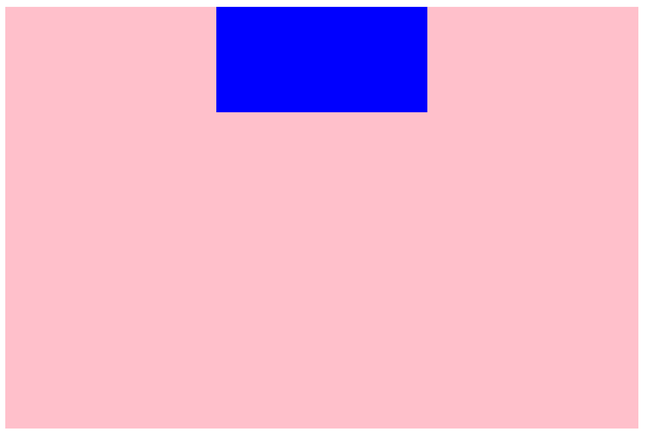

分两步移动：

1. `left: 50%`：子盒子的左边移到父盒子中线，此时整个盒子偏右。
2. 向左移子盒子自身宽度的一半，才能让子盒子中心落在父盒子中线上。

原课先讲负外边距，再优化为位移。下例按课件思路整理：

```css
.father {
    position: relative;
    width: 600px;
    height: 400px;
    background-color: pink;
}
.son {
    position: absolute;
    left: 50%;
    width: 200px;
    height: 100px;
    background-color: blue;
    margin-left: -100px;
}
```

将最后一行替换为：

```css
transform: translateX(-50%);
```

HTML：

```html
<div class="father">
    <div class="son"></div>
</div>
```

**两种50%的参照不同：** `left: 50%` 按父级定位参照区域的宽度计算；`translateX(-50%)` 按子盒子自身宽度计算。位移版本无需在修改子盒子宽度后手动重算负外边距。

**常见错误：** 只写 `left: 50%`，盒子会偏右；忘记给父盒子设置定位，子盒子的参照可能跑到更外层。


### 1.9 水平、垂直都居中

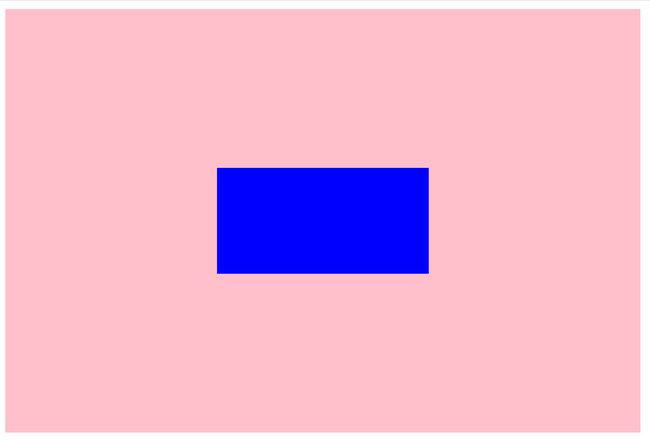

```css
.father {
    position: relative;
}
.son {
    position: absolute;
    left: 50%;
    top: 50%;
    transform: translate(-50%, -50%);
}
```

`left`、`top` 先把子盒子的左上角移到父区域中心；`translate(-50%, -50%)` 再向左、向上各移子盒子自身尺寸的一半。

课堂 `05-定位-绝对定位居中.html` 演示没有已定位祖先时的双向居中：

CSS（放在 `<style>` 内）：

```css
.box {
    /* 1. 绝对定位的盒子不能使用左右margin auto居中 */
    position: absolute;
    /* margin: 0 auto; */
    /* left: 50%, 整个盒子移动到浏览器中间偏右的位置 */
    left: 50%;
    /* 把盒子向左侧移动: 自己宽度的一半 */
    /* margin-left: -150px; */

    top: 50%;
    /* margin-top: -150px; */

    /* 位移: 自己宽度高度的一半 */
    transform: translate(-50%, -50%);

    width: 400px;
    height: 300px;
    background-color: pink;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

**补充：** 源码实际宽度为400px、高度为300px。若使用负外边距，应是 `margin-left: -200px`、`margin-top: -150px`；其中注释的 `margin-left: -150px` 与当前宽度不匹配。当前启用的是百分比位移，结果不受那条注释影响。

**补充：** 本例仅设置 `margin: 0 auto` 不能直接完成绝对定位居中；源码的“不能使用margin auto”不要理解为所有绝对定位条件下都不可能使用自动外边距。本日掌握课件的 `50% + translate` 方法即可。


### 1.10 导航二维码：居中放在文字下方

这是第06天微金所导航的后续细节：导航仍是40px高、1200px版心、五个浮动导航项；二维码位于“手机微金所”下面。

课堂 `06-（案例）导航二维码居中定位案例.html`：

CSS（放在 `<style>` 内）：

```css
* {
  margin: 0;
  padding: 0;
}

/* 因为有通栏：占满一行的边框，所以需要有一个通栏：占满一行的盒子 */
.nav {
  height: 40px;
  border-bottom: 1px solid #ccc;
}

/* 因为ul中所有的内容都是在网页的宽度固定并且水平居中的盒子内部，所以设置ul为宽度固定并且水平居中的效果（后面项目中所用到的版心） */
ul {
  list-style: none;
  width: 1200px;
  margin: 0 auto;
}

ul li {
  float: left;
  width: 20%;
  height: 40px;
  border-right: 1px solid #ccc;
  /* 自动内减 */
  box-sizing: border-box;
  text-align: center;
  line-height: 40px;
}

ul .last {
 border-right: none;
}

ul li a {
  /* a标签默认是行内元素，宽高由内容撑开，并且无法设置宽高，此时默认情况用户只能点击文字区域才能调整 */
  /* 如果把a标签转换成块级元素，此时可以设置宽高，会让a标签范围更大，用户可以点击调整的区域也越大 */
  display: block;
  /* 宽度不设置块元素会默认占满一行 */
  height: 40px;
  text-decoration: none;
  color: #000;
}

ul li .app {
  position: relative;
}

.code {
  position: absolute;
  left: 50%;
  top: 41px;
  transform: translate(-50%);
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 导航 -->
<div class="nav">
  <ul>
    <li><a href="#">我要投资</a></li>
    <li><a href="#">平台介绍</a></li>
    <li><a href="#">新手专区</a></li>
    <!-- 因为用户鼠标放在二维码图片上也能跳转，所以证明img也是在a的范围内，因此把img写在a标签的内部 -->
    <li><a href="#" class="app">手机微金所 <img src="./images/code.jpg" alt="" class="code"> </a></li>
    <li class="last"><a href="#">个人中心</a></li>
  </ul>
</div>
```

代码拆解：

- `.app` 是块级链接，设置相对定位后成为图片的定位参照。
- `.code` 绝对定位，不挤高导航，不遮挡文字本身。
- `left: 50%` 搭配水平负位移，使二维码自身中心对准链接中心。
- `top: 41px` 使图片位于40px高导航下方。
- 图片在 `a` 内，鼠标点击图片也属于点击该链接。

**源码版本区别：** 此课堂版使用 `top: 41px` 和 `transform: translate(-50%)`；只有一个参数的 `translate` 表示水平位移，垂直位移为0。必做完成版使用 `top: 40px`、更明确的 `translateX(-50%)`，并为二维码加1px边框，完整代码见 **4.2**。

**资料中的基础文件：** 未编号的 `（案例）导航二维码居中定位案例.html` 只有 `.app` 的相对定位，尚未插入二维码，也未写 `.code` 的样式，不能把它当完成版。


### 1.11 图片底部半透明遮罩

目标是在1226px × 600px图片区域底部叠放一个150px高的半透明黑色盒子。

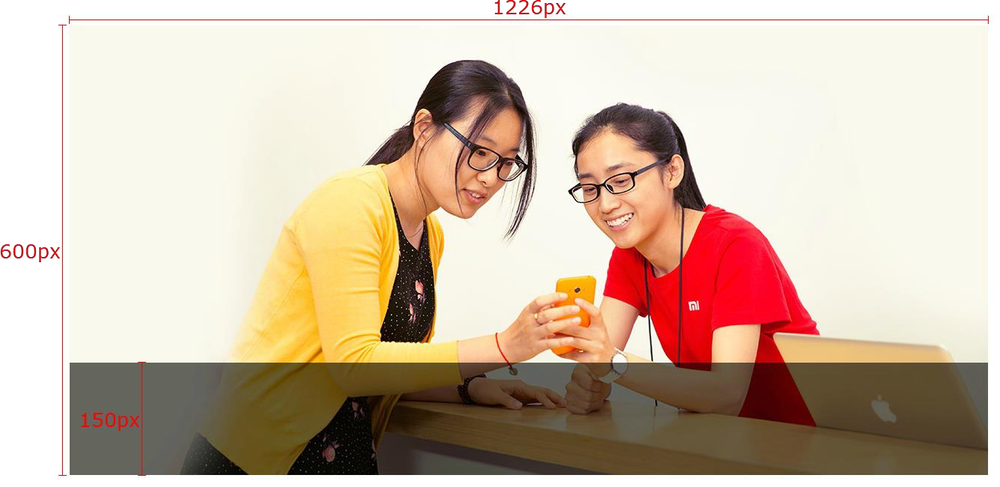

课堂 `07-案例-banner定位.html`：

CSS（放在 `<style>` 内）：

```css
.banner {
    position: relative;
    margin: 0 auto;
    width: 1226px;
    height: 600px;
}

.mask {
    position: absolute;
    left: 0;
    bottom: 0;
    /* 绝对定位的盒子显示模式具备行内块特点: 加宽度高度生效, 如果没有宽度也没有内容, 盒子的宽度尺寸就是0 */
    /* width: 1226px; */
    /* 如果子级和父级的宽度相同  */
    width: 100%;
    height: 150px;
    background-color: rgba(0,0,0, .5);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="banner">
    <img src="./images/bg.jpg" alt="">
    <!-- 遮罩 -->
    <div class="mask">111</div>
</div>
```

定位关系：`.banner` 相对定位，`.mask` 绝对定位，`left: 0; bottom: 0` 贴左下角，`width: 100%` 跟随父区域宽度。

`rgba(0,0,0,.5)` 只让背景颜色半透明，遮罩里的文字不会因此一起变透明。后面 **2.15** 的 `opacity` 则影响整个元素。

**注意：** 绝对定位、固定定位的盒子脱标后，在本课常见的单侧偏移、自动宽度写法下，不会像普通块盒子一样自动铺满父级，需明确设置遮罩宽度。相对定位没有脱标，不属于这里的情况。

**补充：** 课件效果是空遮罩；课堂HTML实际给遮罩写了 `111`，运行时会显示这些文字。笔记保留原代码。


### 1.12 固定定位：页面滚动，屏幕位置保持

```css
position: fixed;
```

本课普通页面中的固定定位特点：参照浏览器可视区域；配合方位属性定位；不占原来的标准流位置。适合固定侧边工具栏、返回顶部等效果。

课堂 `08-定位-固定.html`：

```css
/* css书写: 1. 定位 / 浮动 / display ; 2. 盒子模型; 3. 文字属性 */
.box {
    position: fixed;
    left: 0;
    top: 0;

    /* 
        1. 脱标-不占位置
        2. 改变位置参考浏览器窗口
        3. 具备行内块特点
    */


    width: 200px;
    height: 200px;
    background-color: pink;
}
```

页面中同样放了多段文字和 `<div class="box">box</div>`。滚动页面观察：粉色盒子始终停在可视区域左上角，段落继续在它后面滚动。

**比较：** 相对定位保留占位、参照自己；绝对定位脱标、通常参照最近的已定位祖先；固定定位脱标、本例参照可视区域。

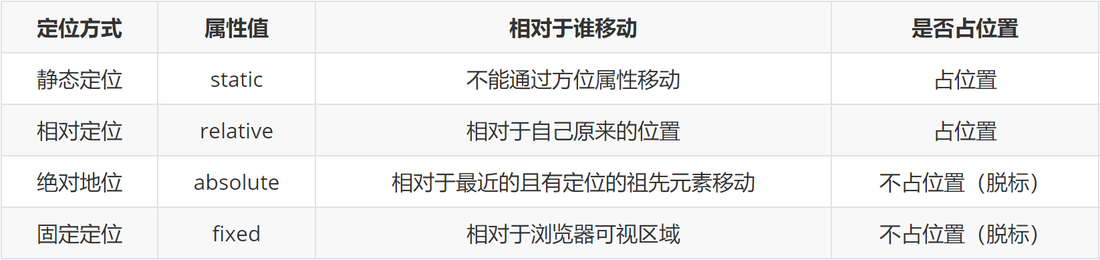

| 方式 | `position` | 本课参照 | 占原位置 | 常见用途 |
| --- | --- | --- | --- | --- |
| 静态 | `static` | 不响应方位偏移 | 占 | 默认排列 |
| 相对 | `relative` | 自己原位置 | 占 | 微调、提供定位参照 |
| 绝对 | `absolute` | 最近的已定位祖先；无则初始包含块 | 不占 | 角标、二维码、遮罩 |
| 固定 | `fixed` | 普通页面的浏览器可视区域 | 不占 | 固定工具栏 |

**补充：** “fixed相对可视区域”适用于本课示例；某些特殊祖先样式（例如祖先设置 `transform`）可改变其参照，不宜把“永远相对浏览器”记成无条件规则。


### 1.13 元素层级与 z-index

课件先用 `标准流 < 浮动 < 定位` 理解简单盒子的覆盖关系；同类定位盒子默认重叠时，HTML中后写的通常盖住先写的。

本课用 `z-index` 修改定位盒子的叠放次序，同一可比较环境中，数值越大越靠上：

```css
.box {
    position: relative;
    z-index: 1;
}
```

课堂 `09-定位-层级关系.html`：

CSS（放在 `<style>` 内）：

```css
div {

    width: 200px;
    height: 200px;
}

.one {
    position: absolute;
    left: 20px;
    top: 50px;

    z-index: 1;

    background-color: pink;
}

.two {
    position: absolute;
    left: 50px;
    top: 100px;

    background-color: skyblue;
}

/* 
    默认情况下, 定位的盒子  后来者居上 ,
    z-index:整数; 取值越大, 显示顺序越靠上, z-index的默认值是0
    注意: z-index必须配合定位才生效
*/
```

HTML（放在 `<body>` 内）：

```html
<div class="one">one</div>
<div class="two">two</div>
```

**当前结果：** `.two` 在HTML中后写；但 `.one` 设置了 `z-index: 1`，因此本例重叠区域由粉色 `.one` 盖住蓝色 `.two`。注释掉这行后可观察默认的“后来者居上”。

**补充：** 源码注释把 `z-index` 默认值写成0，实际默认是 `auto`。本课在定位元素上使用它；“z-index只能用于定位元素”不作为所有CSS布局的绝对规则。

**补充：** 课件的层级口诀只用于本课简单示例。不同祖先形成的叠放环境会限制比较，不能保证一个后代写再大的数字就盖住整个页面；本日不展开复杂层叠规则。


## 2. 装饰

主体布局完成后，再处理图片和文字对齐、鼠标样式、圆角、溢出与显示隐藏。下面按原课顺序整理，五个垂直对齐案例对应 `-bug垂直对齐` 与 `10-垂直对齐` 两组文件。


### 2.1 基线：为什么图片和文字底部不齐

浏览器在一行中排文字时，以基线（baseline）作为对齐依据。基线不等于字形的最底部，某些字母会伸到基线以下。

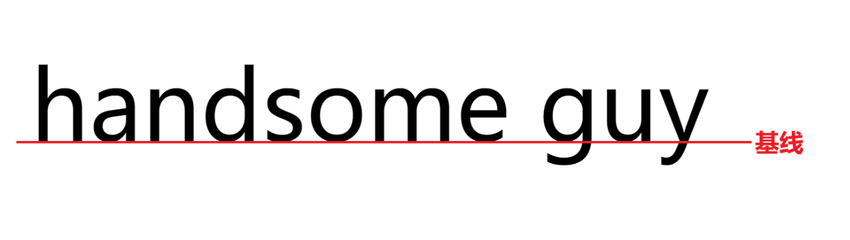

行内、行内块内容在行内排版中默认按基线对齐。图片底部通常对齐这一行的基线；为了容纳基线下方的文字部分，行框可能留出空间。

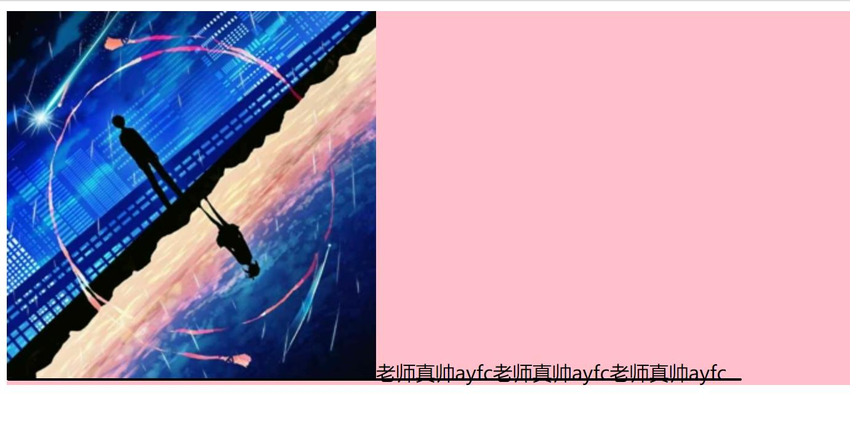

所以看到图片下方有一小条空隙，先检查行内排版的基线问题，不能直接认定图片本身有边框、外边距或透明像素。


### 2.2 vertical-align 的基本使用

`vertical-align` 调整本课行内、行内块元素在行中的垂直对齐方式，通常写在需要对齐的 `img` 或 `input` 上。

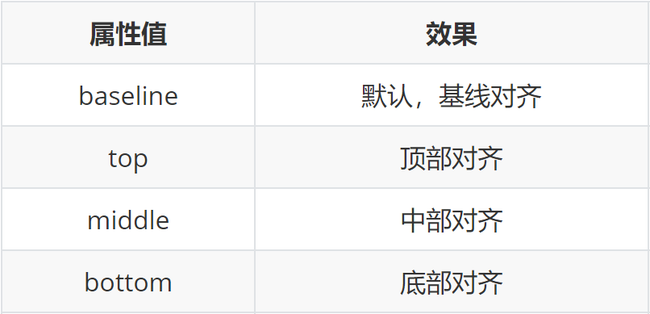

| 值 | 本课理解 |
| --- | --- |
| `baseline` | 默认按基线对齐 |
| `top` | 对齐行框顶部 |
| `middle` | 调整为中部对齐，常用于图片与文字、控件之间 |
| `bottom` | 对齐行框底部 |

```css
img {
    vertical-align: middle;
}
```

**补充：** `middle` 的对齐基准和当前行的文字有关，不是“任意盒子在父盒子中精确垂直居中”。给普通块级 `div` 写这条属性不能直接让它在父盒子内居中。

原课建议在已经学过浮动的范围内，用浮动完成多个 `div` 的横向排列，减少行内块基线带来的对齐问题；这条建议是本课的布局选择，不表示所有场景都只能使用浮动。


### 2.3 问题一：文本框与按钮不齐

原始文件给两个 `input` 只设置 `height: 50px`；默认基线和控件盒子尺寸处理可能导致文本框与按钮的边缘不齐。

修复版 `10-垂直对齐/01-（案例）vertical-algin解决问题一.html`：

CSS（放在 `<style>` 内）：

```css
/* 浏览器遇到行内和行内块标签当做文字处理, 默认文字是按基线对象 */
input {
  height: 50px;
  box-sizing: border-box;

  vertical-align: middle;
}
```

HTML（放在 `<body>` 内）：

```html
<input type="text"><input type="button" value="搜索">
```

两条新增声明各有作用：`box-sizing: border-box` 让50px包含边框和内边距，统一外部高度；`vertical-align: middle` 统一行内对齐方式。只改对齐属性未必能解决不同盒模型造成的外部高度差。

**观察：** 文本框和“搜索”按钮应在同一行协调对齐。两标签之间没有空白文字；本例主要不是处理水平方向的标签空格。


### 2.4 问题二：图片与 input 不齐

原始文件只有同一行的图片和文本框，没有CSS。修复版把图片的对齐方式改为 `middle`：

CSS（放在 `<style>` 内）：

```css
img {
  vertical-align: middle;
}
```

HTML（放在 `<body>` 内）：

```html
<img src="../images/1.jpg" alt=""><input type="text">
```

观察图片和文本框在同一行中的相对位置。此处调整的是行内垂直对齐，没有修改图片尺寸，也没有定位或浮动。

`../images/1.jpg` 表示从当前 `10-垂直对齐` 目录先返回上一级，再进入课堂的 `images` 目录。复制案例时需要保留这个相对路径关系。


### 2.5 问题三：父盒子里的文本框不能贴顶

原始文件有400px × 400px粉色父盒子，内部只有文本框；默认基线排版使控件顶部未必紧贴父盒子内容顶部。

修复版：

CSS（放在 `<style>` 内）：

```css
.father {
  width: 400px;
  height: 400px;
  background-color: pink;
}

input {
  /* vertical-align: middle; */
  vertical-align: top;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
  <input type="text">
</div>
```

当前启用的是 `vertical-align: top`，`middle` 被注释。它让文本框对齐当前行顶部；在本例父盒子没有内边距等额外距离的条件下，获得贴顶效果。

若父盒子本身有 `padding-top`，控件仍会从父盒子内容区域顶部开始，不会跨过内边距贴到外边框。


### 2.6 问题四：图片撑开的父盒子底部有缝

原始父盒子只设置宽度400px，没设高度，由图片和行框撑开。图片默认按基线对齐，下面可能留下用于文字的空间。

修复版：

CSS（放在 `<style>` 内）：

```css
.father {
  width: 400px;
  background-color: pink;
}

img {
  /* 浏览器把行内和行内块标签当做文字处理,默认基线对齐 */
  /* vertical-align: middle; */
  display: block;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
  <img src="../images/1.jpg" alt="">
</div>
```

**当前真正生效的方法是 `display: block`。** 图片变为块级盒子后，不再以原来的行内基线方式参与那一行排版，父盒子的底部缝隙随之消失。

课堂还保留了 `vertical-align: middle` 的注释，可取消 `display: block`，改用该行观察另一种处理方式。两者的用途不同：需要图片独占一行时用块级；还要和文字、表单控件同排时优先调整垂直对齐。

**常见错误：** 把已注释的 `vertical-align` 当当前修复方法，或给父盒子随意加负外边距掩盖空隙。


### 2.7 问题五：配合行高让图片居中

原始父盒子宽高600px，已经有 `line-height: 600px`，但图片仍默认按基线对齐，仅设置行高不足以得到期望的图片居中。

修复版增加 `text-align: center` 和图片的 `vertical-align: middle`：

CSS（放在 `<style>` 内）：

```css
.father {
  width: 600px;
  height: 600px;
  background-color: pink;
  line-height: 600px;
  text-align: center;
}

img {
  vertical-align: middle;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
  <img src="../images/1.jpg" alt="">
</div>
```

职责分开理解：父级 `text-align: center` 控制行内图片的水平居中；父级大行高配合图片的 `middle` 调整垂直位置。

**补充：** 该方法适合本课单行图片演示，`middle` 仍受文字基准影响；不要把它当所有内容都能精确居中的通用方法。需要子盒子双向居中时，可用前面的 `子绝父相 + 50% + translate`。

五个案例复习对照：

| 原问题 | 完成版主要变化 |
| --- | --- |
| input与按钮边缘不齐 | `border-box` 加 `vertical-align: middle` |
| 图片与input不齐 | 图片 `vertical-align: middle` |
| 文本框不贴顶 | input `vertical-align: top` |
| 图片底部缝隙 | 当前用图片 `display: block` |
| 行高不能单独让图片居中 | 父级水平对齐，图片 `middle` 配合行高 |


### 2.8 光标类型 cursor

`cursor` 设置鼠标移到元素上时显示的光标，用外观提示当前区域能做什么。

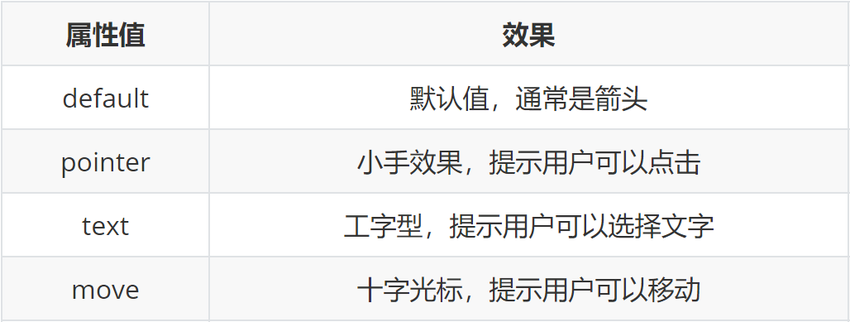

| 值 | 常见外观与用途 |
| --- | --- |
| `default` | 箭头 |
| `pointer` | 小手，提示可点击 |
| `text` | 工字形，提示可选择文字 |
| `move` | 移动光标，提示可拖动 |

课堂 `11-光标类型.html`：

CSS（放在 `<style>` 内）：

```css
div {
    width: 200px;
    height: 200px;
    background-color: pink;

    /* 手型 */
    /* cursor: pointer; */

    /* 工字型, 表示可以复制 */
    /* cursor: text; */

    /* 十字型, 表示可以移动 */
    cursor: move;

}
```

HTML（放在 `<body>` 内）：

```html
<div>div</div>
```

当前启用的是 `cursor: move`，手型和工字形的写法被注释，可分别切换观察。

**补充：** 光标只改变提示外观，写 `pointer` 不会自动添加链接，写 `move` 也不会自动实现拖拽。源码把 `text` 描述为“可以复制”，更准确的是文字选择提示。


### 2.9 边框圆角 border-radius

`border-radius` 让盒子的角变圆。常见取值为 `px` 长度或百分比，即使没有可见边框也能让背景角变圆。

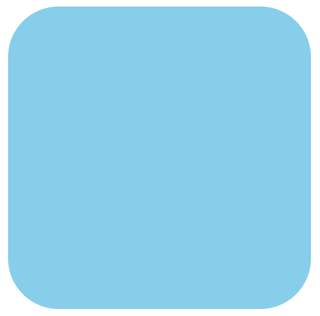

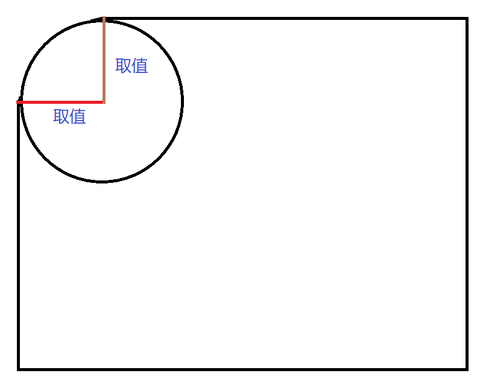

四角的顺序从左上角开始，顺时针：**左上 → 右上 → 右下 → 左下**。

| 值的数量 | 示例 | 左上 / 右上 / 右下 / 左下 |
| --- | --- | --- |
| 1个 | `10px` | 10 / 10 / 10 / 10 |
| 2个 | `10px 80px` | 10 / 80 / 10 / 80 |
| 3个 | `10px 40px 80px` | 10 / 40 / 80 / 40 |
| 4个 | `10px 20px 40px 80px` | 10 / 20 / 40 / 80 |

记忆原课口诀：从左上顺时针赋值；缺少的角看对角。

课堂 `12-圆角边框-基本使用.html`：

CSS（放在 `<style>` 内）：

```css
.box {
    margin: 50px auto;
    width: 200px;
    height: 200px;
    background-color: pink;

    /* 一个值: 表示4个角是相同的 */
    border-radius: 10px;

    /* 4值: 左上  右上   右下   左下 -- 从左上顺时针转一圈 */
    /* border-radius: 10px 20px 40px 80px; */

    /* border-radius: 10px 40px 80px; */

    /* border-radius: 10px 80px; */
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

当前只有 `border-radius: 10px` 生效，因此四角都为10px。其他声明是供切换的注释，不能把它们都当成当前效果。

**易错点：** 这里的四值顺序是四个角，和 `margin`、`padding` 的“上右下左”不同。


### 2.10 圆角应用：正圆与胶囊

正圆：盒子必须是正方形，圆角取宽高的一半，通常写 `50%`。

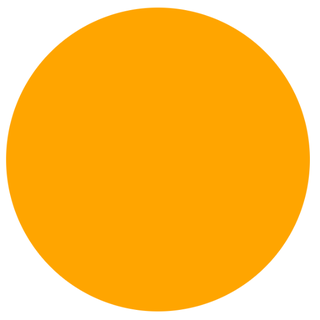

胶囊：盒子是横向长方形，圆角取高度的一半。

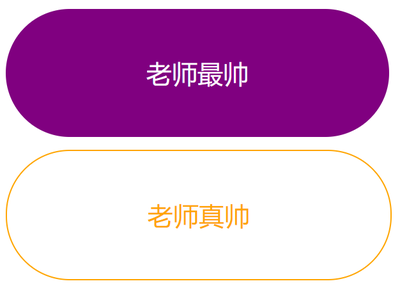

课堂 `13-圆角边框-工作常见场景.html`：

CSS（放在 `<style>` 内）：

```css
.one {
    width: 200px;
    height: 200px;
    background-color: pink;

    /* border-radius: 100px; */
    /* 50% : 取盒子尺寸的一半 */
    border-radius: 50%;
}

/* 胶囊状: 长方形, border-radius取值是高度的一半 */
.two {
    width: 400px;
    height: 200px;
    background-color: skyblue;

    border-radius: 100px;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="one"></div>

<div class="two"></div>
```

当前 `.one` 为200px × 200px、圆角50%，显示正圆；`.two` 为400px × 200px、圆角100px，显示胶囊。

**补充：** 横向长方形写 `border-radius: 50%` 常会得到椭圆，不能把“50%画圆”直接套到所有长宽比例。胶囊按高度一半设置固定长度即可。


### 2.11 overflow：控制超出盒子的内容

溢出部分是内容超出盒子范围的区域。`overflow` 控制这些部分显示、裁切还是滚动。

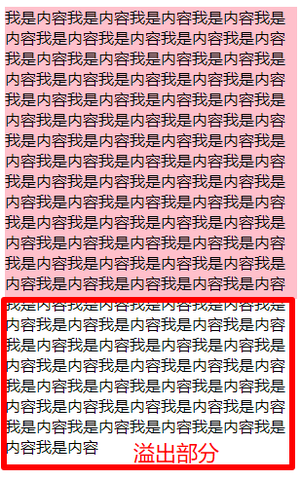

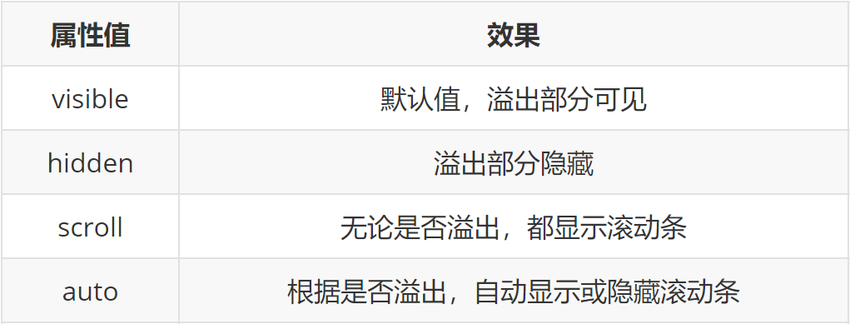

| 值 | 效果 |
| --- | --- |
| `visible` | 默认溢出可见 |
| `hidden` | 超出部分被裁切 |
| `scroll` | 提供滚动机制，传统滚动条通常保留位置 |
| `auto` | 根据是否溢出决定是否需要滚动条 |

课堂 `14-overflow.html`：

CSS（放在 `<style>` 内）：

```css
.box {
    width: 300px;
    height: 300px;
    background-color: pink;

    /* 溢出隐藏 */
    overflow: hidden;

    /* 滚动: 无论内容是否超出都显示滚动条的位置 */
    /* overflow: scroll; */

    /* auto: 根据内容是否超出, 判断是否显示滚动条 */
    /* overflow: auto; */
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">我是div,测试溢出显示效果我是div</div>
```

当前启用 `overflow: hidden`；但HTML只有一小段文字，通常不会超过300px高，所以直接打开不一定看得到裁切。可在 `.box` 内重复粘贴这段文字直到超出盒子，再依次切换三个值观察。

**补充：** `scroll` 的滚动条外观和是否持续显示也受系统、浏览器设置影响，课件的“总显示滚动条”是常见演示效果。

**区分：** `overflow: hidden` 隐藏的是超出的内容，不是让整个盒子消失；盒子本身仍正常存在。二维码、hot角标如果超出父盒子，父级裁切也可能让它们显示不完整。


### 2.12 元素隐藏：display 与 visibility

| 写法 | 元素可见吗 | 原布局位置 |
| --- | --- | --- |
| `visibility: hidden` | 不可见 | 保留 |
| `display: none` | 不可见，元素及后代不显示 | 不再占据布局位置 |

课堂 `15-隐藏效果.html`：

CSS（放在 `<style>` 内）：

```css
div {
    width: 200px;
    height: 200px;
}

.one {
    /* 占位隐藏 */
    /* visibility: hidden; */

    /* **** 不占位隐藏 */
    display: none;

    background-color: pink;
}

.two {
    background-color: green;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="one">one</div>
<div class="two">two</div>
```

**当前结果：** 粉色 `.one` 使用 `display: none`，绿色 `.two` 按前面没有该盒子来排列。改为 `visibility: hidden` 后，粉色盒子看不到，但它的200px高位置仍保留，绿色盒子在其后。

本课常通过 `display: none` 隐藏、`display: block` 显示完成切换。

**补充：** 恢复显示应匹配元素实际需要的显示模式。原本需要行内或行内块的元素，不必一律恢复为 `block`；本课二维码和遮罩的完成代码使用 `block`。

**注意：** 一个元素原先若已绝对定位，隐藏前本就不占标准流位置。比较两种隐藏方式的“占位”差别时，先用当前两个普通块盒子的示例观察。


### 2.13 鼠标移入父元素，让子元素显示

课件第64页要求：默认 `.son` 隐藏，鼠标移入 `.father` 后显示。以下根据原课需求整理成一个最小示例：

```html
<div class="father">
    <div class="son"></div>
</div>
```

```css
.father {
    width: 400px;
    height: 400px;
    background-color: pink;
}
.son {
    display: none;
    width: 100px;
    height: 100px;
    background-color: blue;
}
.father:hover .son {
    display: block;
}
```

`.father:hover .son` 表示“父元素处于悬停状态时，选中里面的 `.son`”。悬停条件放在始终存在的父元素上，被切换的是子元素。

**常见错误：** 写 `.son:hover` 试图让已 `display: none` 的子元素自己出现；元素没有显示区域，鼠标无法先移到它上面触发悬停。


### 2.14 导航二维码的显示隐藏切换

在 **1.10** 居中定位基础上，二维码默认隐藏，鼠标悬停导航链接时出现，移开后消失。

课堂 `16-（案例）导航二维码居中定位案例-显示隐藏效果.html` 的CSS：

```css
* {
  margin: 0;
  padding: 0;
}

/* 因为有通栏：占满一行的边框，所以需要有一个通栏：占满一行的盒子 */
.nav {
  height: 40px;
  border-bottom: 1px solid #ccc;
}

/* 因为ul中所有的内容都是在网页的宽度固定并且水平居中的盒子内部，所以设置ul为宽度固定并且水平居中的效果（后面项目中所用到的版心） */
ul {
  list-style: none;
  width: 1200px;
  margin: 0 auto;
}

ul li {
  float: left;
  width: 20%;
  height: 40px;
  border-right: 1px solid #ccc;
  /* 自动内减 */
  box-sizing: border-box;
  text-align: center;
  line-height: 40px;
}

ul .last {
 border-right: none;
}

ul li a {
  /* a标签默认是行内元素，宽高由内容撑开，并且无法设置宽高，此时默认情况用户只能点击文字区域才能调整 */
  /* 如果把a标签转换成块级元素，此时可以设置宽高，会让a标签范围更大，用户可以点击调整的区域也越大 */
  display: block;
  /* 宽度不设置块元素会默认占满一行 */
  height: 40px;
  text-decoration: none;
  color: #000;
}

ul li .app {
  position: relative;
}

.code {
  position: absolute;
  left: 50%;
  top: 41px;

  display: none;

  transform: translate(-50%);


}

/* 鼠标悬停a 显示二维码图片 */
.nav li a:hover img {
    display: block;
}
```

HTML沿用 **1.10**，二维码仍放在 `.app` 链接里。新增关键代码是 `.code { display: none; }` 和 `.nav li a:hover img { display: block; }`。

**选择器读法：** 悬停 `.nav` 中某个 `li` 的 `a` 时，显示该链接内的图片。本例只有手机微金所链接包含二维码；必做完成版改用 `.app:hover .code`，目标更明确。

**补充：** 课堂版二维码 `top: 41px`，链接高40px，两者间有1px空隙。鼠标从链接移动到二维码时，如果经过这条空隙，可能短暂失去悬停而隐藏。必做版使用 `top: 40px`，可让二维码区域接上链接底部；完整参考见 **4.3**。二维码在链接内，鼠标处于其可见区域时仍属于链接的悬停范围。


### 2.15 原课拓展：元素整体透明度 opacity

`opacity` 使用0～1的数值：1完全不透明，0完全透明，0.5半透明。它影响元素整体，包括文字、图片和子元素。

课堂 `17-拓展-opacity.html`：

CSS（放在 `<style>` 内）：

```css
div {
    width: 400px;
    height: 400px;
    background-color: green;

    opacity: 0.5;
}
```

HTML（放在 `<body>` 内）：

```html
<div>
    <img src="./images/product.png" alt="">
    这个字透明吗
</div>
```

当前绿色盒子设置0.5，里面的图片与“这个字透明吗”也会一起变透明。

| 需求 | 本课写法 |
| --- | --- |
| 只让黑色背景半透明，文字保持正常 | `background-color: rgba(0,0,0,.5)` |
| 整个盒子及里面内容一起半透明 | `opacity: .5` |

**补充：** `opacity: 0` 只是透明，元素仍参与原有布局，也仍可能接收鼠标操作；不能把它等同于 `display: none`。父级整体透明后，子元素写 `opacity: 1` 也不能把父级合成透明度抵消掉。


### 2.16 原课拓展：表格边框合并

相邻单元格各有边框时，默认分离显示可能显得像两条边框。给 `table` 设置 `border-collapse: collapse`，可让相邻边框合并，得到细线表格。

合并前：

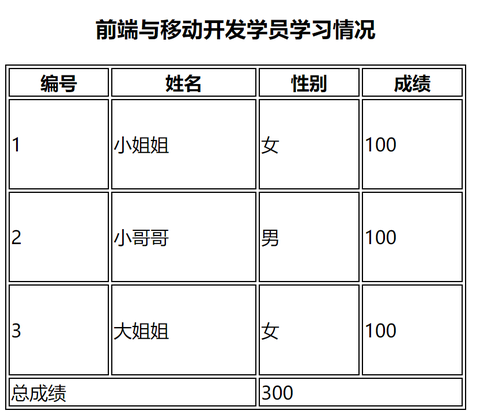

合并后：

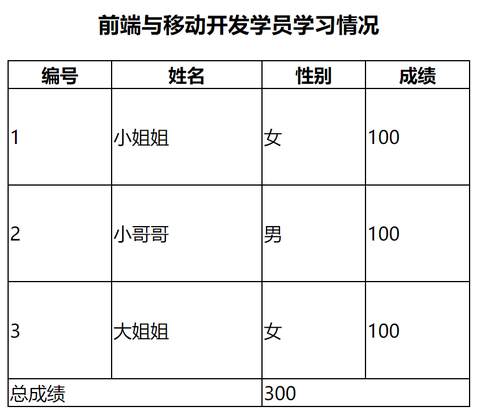

课堂 `18-（拓展）边框合并.html`：

CSS（放在 `<style>` 内）：

```css
table {
  border: 1px solid #000;

  /* 注意: 一定要加给table标签 : 做细线表格 */
  border-collapse: collapse;
}

th,
td {
  border: 1px solid #000;
}
```

HTML（放在 `<body>` 内）：

```html
<!--  border="1" width="400" height="300"cellspacing="0" -->
<table>
  <caption><h3>前端与移动开发学员学习情况</h3></caption>
  <thead>
    <tr>
      <th>编号</th>
      <th>姓名</th>
      <th>性别</th>
      <th>成绩</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>小姐姐</td>
      <td>女</td>
      <td>100</td>
    </tr>
    <tr>
      <td>2</td>
      <td>小哥哥</td>
      <td>男</td>
      <td>100</td>
    </tr>
    <tr>
      <td>3</td>
      <td>大姐姐</td>
      <td>女</td>
      <td>100</td>
    </tr>
  </tbody>
  <tfoot>
    <tr>
      <td colspan="2">总成绩</td>
      <td colspan="2">300</td>
    </tr>
  </tfoot>
</table>
```

属性写在 `table` 上；`th`、`td` 的 `border` 仍负责提供可见边框。只写合并属性，不写单元格边框，不会自动画出全部表格线。

**区分：** `border-collapse` 合并相邻边框；HTML的 `colspan` 合并单元格跨列范围，两者职责不同。


### 2.17 原课拓展：用边框画三角形

原理：盒子的四条边框在角部相接，内容宽高为0时，四个方向的边框会形成四块三角形。

实现步骤：

1. 先建一个盒子，给四条边框不同颜色，观察边框交接。
2. 将内容宽度和高度设为0，只剩边框区域。
3. 保留一个方向的边框颜色，其他方向颜色改为 `transparent`。
4. 调整各边框宽度，可改变三角形的大小和比例。

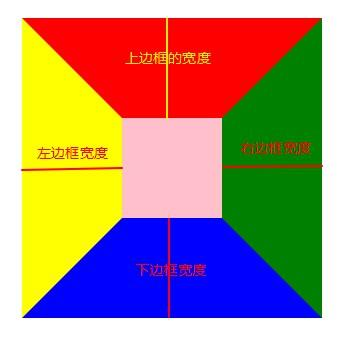

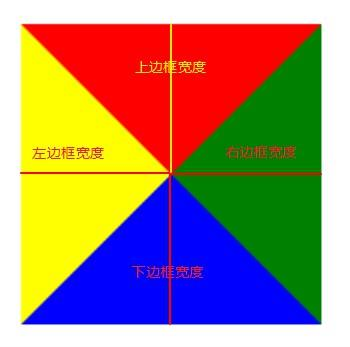

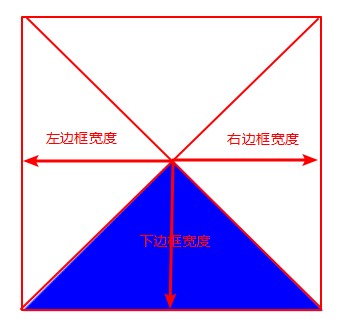

课堂 `19-拓展-css书写三角形.html`：

CSS（放在 `<style>` 内）：

```css
div {
    /* width: 100px;
    height: 100px; */
    width: 0;
    height: 0;
    /* background-color: pink; */
    /* transparent: 透明 */
    border-top: 10px solid transparent;
    border-right: 10px solid transparent;
    border-bottom: 10px solid transparent;
    border-left: 10px solid orange;
}

/* 
    1. 书写一个盒子
    2. 盒子添加四个方向的border, 颜色设置不同
    3. 保留其中一个方向的border, 其他方向颜色是transparent
*/
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```

**当前课堂代码：** 保留橙色左边框，另外三条边框透明，得到一个向右指的橙色三角形。课件示意图保留的是下边框，得到向上的蓝色三角形；图和代码展示的方向不同。

| 保留的有色边框 | 三角形指向 |
| --- | --- |
| `border-top` | 向下 |
| `border-right` | 向左 |
| `border-bottom` | 向上 |
| `border-left` | 向右 |

四条边框均为10px时，当前右向三角形的可见竖向底边为20px、水平高度为10px。虽然内容宽高为0，边框仍会形成实际占用的区域。

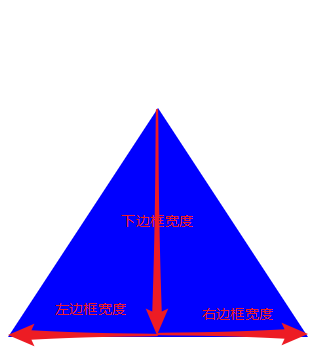

**常见错误：** 删除其他三条边框，而不是设为透明，会改变交接形状；忘记将内容宽高设为0，则通常得到围着内容区域的边框。


## 3. 选择器拓展

前面已用过 `:hover`。本节继续学习根据元素状态以及HTML属性选择元素，注意分清“处于某种状态”和“具有某个属性”。


### 3.1 链接伪类：LVHA 顺序

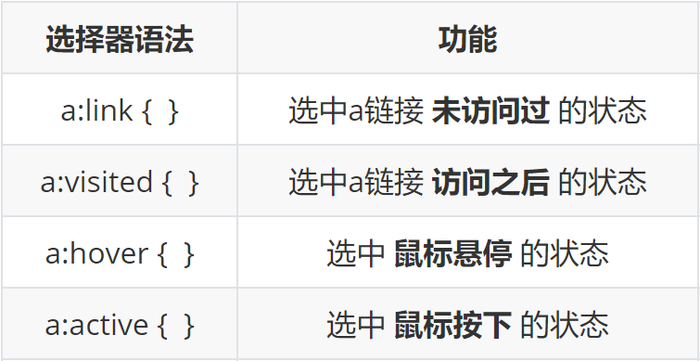

| 选择器 | 状态 |
| --- | --- |
| `a:link` | 链接尚未访问 |
| `a:visited` | 链接已经访问 |
| `a:hover` | 鼠标悬停 |
| `a:active` | 激活期间，本课常见为鼠标按下未松开 |

根据课件语法整理的示例：

```html
<a href="https://www.itheima.com/">黑马程序员</a>
```

```css
a:link {
    color: blue;
}
a:visited {
    color: purple;
}
a:hover {
    color: orange;
}
a:active {
    color: red;
}
```

同时写四种效果时，本课使用 **LVHA**：`link → visited → hover → active`。这些规则可能同时匹配，选择器权重相同时后写的声明覆盖同一属性，所以顺序关系影响悬停和按下的效果。

`:hover` 使用最频繁，也能用于 `div`、`li` 等其他元素，本日前面的显示隐藏案例就是这种用法。

**补充：** `:active` 不是“访问后一直保持选中”，也不是导航当前页面标记。测试 `:visited` 要用带 `href` 的真实链接，并注意浏览器访问历史和隐私限制；不必用它判断业务状态。


### 3.2 焦点伪类 :focus

`E:focus` 选择当前获得焦点的元素，常用于表单控件。点击文本框，或用键盘Tab切换到控件，都可能使它获得焦点；焦点转移后不再匹配。

课堂 `20-拓展-焦点伪类选择器.html`：

CSS（放在 `<style>` 内）：

```css
/* 获得焦点的状态 */
/* 获得焦点: 把光标点到input里面; 失去焦点: 把光标从input里面拿出来 */
input:focus {
    background-color: pink;
}
```

HTML（放在 `<body>` 内）：

```html
<input type="text">
<input type="password">
<input type="button">
```

当前匹配所有获取焦点的 `input`，不仅是文本框。文本框、密码框、按钮被聚焦时背景变粉色；失焦后恢复原样。

浏览器常为获焦控件提供外部轮廓线，用于提示焦点。它不同于写在控件盒子上的普通边框。

**区分：** `:hover` 看鼠标是否悬停；`:focus` 看焦点所在位置。鼠标移出文本框后，只要焦点没转移，`:focus` 效果仍可保持。


### 3.3 属性选择器

属性选择器根据元素上的HTML属性进行匹配。本课讲两种基础写法：

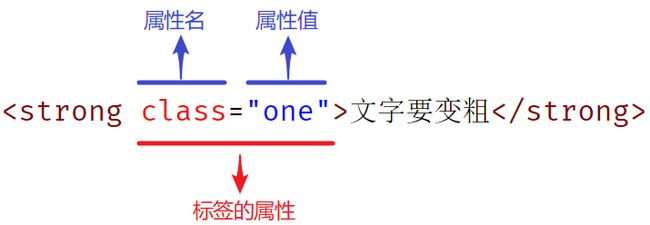

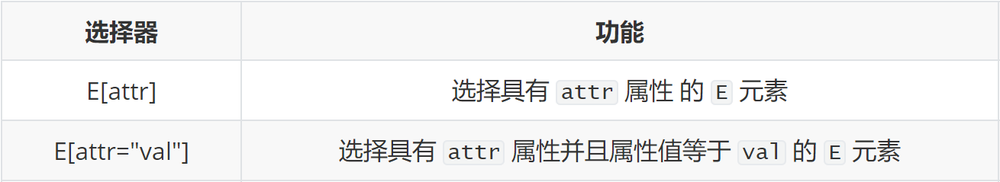

| 写法 | 含义 | 例子 |
| --- | --- | --- |
| `E[attr]` | E元素具有attr属性 | `input[type]` |
| `E[attr="val"]` | E元素具有attr属性，且其值匹配val | `input[type="text"]` |

课堂 `21-拓展-属性选择器.html`：

CSS（放在 `<style>` 内）：

```css
/* text:背景色是粉色; password背景色是skyblue */
input[type='text']  {
    background-color: pink;
}

input[type="password"] {
    background-color: skyblue;
}

/* input:nth-child(1) {} */
```

HTML（放在 `<body>` 内）：

```html
<input type="text">
<input type="password">
```

文本框背景为粉色，密码框背景为天蓝色。单引号和双引号都可以表示属性值。

与 `input:nth-child(1)` 相比，`input[type="text"]` 表达的是控件类型；在页面中插入其他兄弟元素后，不会因为序号变化就选中不同类型的控件。

**补充：** 匹配依据是HTML属性，不是CSS属性。`input[type]` 要求标签上实际存在 `type` 属性；省略 `type` 的input虽然默认表现为文本框，也不能简单当成具有 `type="text"` 的属性来匹配。


## 4. 原课练习与复习

以下先按必做编号完成三个案例，再选择遮罩或项目练习。完整参考代码保留原文件内容，图片路径仍按各自案例目录解释。


### 4.1 必做一：卡片模块 hot 图片

原目录：`04-作业/01-综合案例（必做）/01-综合案例1-卡片模块hot图片案例`。

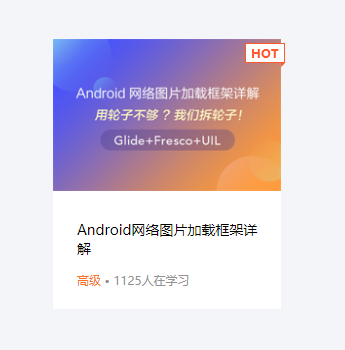

基础版已经完成228px × 270px卡片、产品图、标题和学习人数。完成版只需要增加定位细节：

1. `.box` 新增 `position: relative`。
2. 卡片内插入 `class="hot"` 的图片。
3. `.hot` 新增绝对定位、`top: 4px`、`right: -4px`。

原完成文件 `02-卡片模块hot图片案例-完成样式.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    /* 清除标签默认的margin和padding */
    * {
      margin: 0;
      padding: 0;
    }

    body {
      background-color: #f4f5f9;
    }

    .box {
      position: relative;
      /* 1、宽高 */
      width: 228px;
      height: 270px;
      /* 2、背景颜色 */
      background-color: #fff;
      margin: 100px auto;
    }

    .box .product {
      /* width: 228px; */
      width: 100%;
    }

    .box h3 {
      height: 52px;
      padding-left: 24px;
      padding-right: 20px;
      margin-top: 25px;
      font-size: 14px;
      font-weight: 400;
    }

    .box p {
      margin-left: 24px;
      font-size: 12px;
      color: #929292;
    }

    .box p span {
      color: #f77321;
    }

    /* 设置hot定位 */
    .hot {
      position: absolute;
      top: 4px;
      right: -4px;
    }

  </style>
</head>
<body>
  <!-- 布局流程：从上往下、从外往内 -->
  <div class="box">
    <img src="./images/hot.png" alt="" class="hot">
    <img src="./images/product.png" alt="" class="product">
    <h3>Android网络图片加载框架详解</h3>
    <p><span>高级</span> • 1125人在学习</p>
  </div>
</body>
</html>
```

检查结果：hot贴在卡片右上角并略微伸出；产品图、标题和人数没有被角标挤开；改变卡片在页面中的位置后，角标仍跟随该卡片。

**常见错误：** 忘记父级定位，角标跑到外层；把 `right: -4px` 写成正4px，角标缩进卡片；给所有 `img` 写 `width: 100%`，使小角标也被拉宽。原代码用 `.product` 单独控制主图宽度。

练习顺序：先在基础文件上完成，再对照完成文件；随后在学成在线前两张课程卡片上做相同效果，对应 **1.7**。


### 4.2 必做二：导航二维码居中

原目录：`04-作业/01-综合案例（必做）/02-综合案例2-导航二维码居中定位案例`。

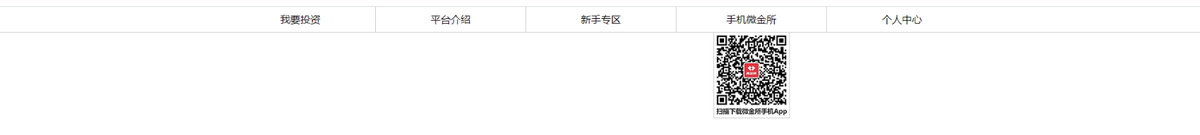

基础版没有二维码。完成步骤：将二维码放进手机微金所链接；`.app` 相对定位；`.code` 绝对定位，`left: 50%` 加 `translateX(-50%)` 水平居中，`top: 40px` 避开文字，并加1px灰色边框。

原完成文件 `02-导航二维码居中定位案例-完成样式.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    * {
      margin: 0;
      padding: 0;
    }

    /* 因为有通栏：占满一行的边框，所以需要有一个通栏：占满一行的盒子 */
    .nav {
      height: 40px;
      border-bottom: 1px solid #ccc;
    }

    /* 因为ul中所有的内容都是在网页的宽度固定并且水平居中的盒子内部，所以设置ul为宽度固定并且水平居中的效果（后面项目中所用到的版心） */
    ul {
      list-style: none;
      width: 1200px;
      margin: 0 auto;
    }

    ul li {
      float: left;
      width: 20%;
      height: 40px;
      border-right: 1px solid #ccc;
      /* 自动内减 */
      box-sizing: border-box;
      text-align: center;
      line-height: 40px;
    }

    ul .last {
     border-right: none;
    }

    ul li a {
      /* a标签默认是行内元素，宽高由内容撑开，并且无法设置宽高，此时默认情况用户只能点击文字区域才能调整 */
      /* 如果把a标签转换成块级元素，此时可以设置宽高，会让a标签范围更大，用户可以点击调整的区域也越大 */
      display: block;
      /* 宽度不设置块元素会默认占满一行 */
      height: 40px;
      text-decoration: none;
      color: #000;
    }

    ul li .app {
      position: relative;
    }

    ul li .app .code {
      /* 子绝父相 */
      position: absolute;
      left: 50%;
      transform: translateX(-50%);
      /* 为了img标签不遮住a标签的主体内容 */
      top: 40px;
      border: 1px solid #ccc;
    }
  </style>
</head>
<body>
  <!-- 导航 -->
  <div class="nav">
    <ul>
      <li><a href="#">我要投资</a></li>
      <li><a href="#">平台介绍</a></li>
      <li><a href="#">新手专区</a></li>
      <!-- 因为用户鼠标放在二维码图片上也能跳转，所以证明img也是在a的范围内，因此把img写在a标签的内部 -->
      <li><a href="#" class="app">手机微金所<img src="./images/code.jpg" alt="" class="code"></a></li>
      <li class="last"><a href="#">个人中心</a></li>
    </ul>
  </div>

</body>
</html>
```

**本阶段二维码默认可见**，不含显示隐藏的要求。

尺寸理解：版心1200px，五个 `li` 各为20%；`box-sizing: border-box` 让分隔边框计入每个导航项总宽，避免额外边框将最后一项挤下去。二维码参照具体链接宽度居中，不是参照整条1200px导航。

检查结果：二维码中心在“手机微金所”对应导航项的中心线上；不遮住文字；导航高度不被图片撑大；点击二维码仍属于链接区域。


### 4.3 必做三：二维码显示隐藏切换

原目录：`04-作业/01-综合案例（必做）/03-综合案例3-导航二维码显示隐藏切换案例`。

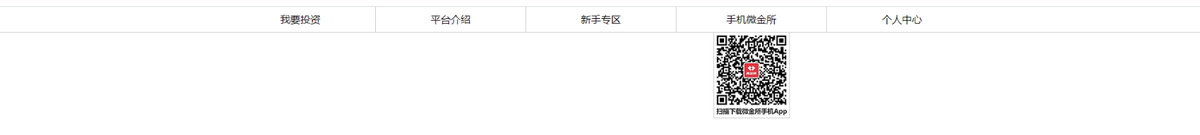

基础版沿用上一项的居中完成效果。再增加两件事：

- `.code` 默认 `display: none`。
- `.app:hover .code` 设置 `display: block`。

原完成文件 `02-导航二维码显示隐藏切换案例-完成样式.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    * {
      margin: 0;
      padding: 0;
    }

    /* 因为有通栏：占满一行的边框，所以需要有一个通栏：占满一行的盒子 */
    .nav {
      height: 40px;
      border-bottom: 1px solid #ccc;
    }

    /* 因为ul中所有的内容都是在网页的宽度固定并且水平居中的盒子内部，所以设置ul为宽度固定并且水平居中的效果（后面项目中所用到的版心） */
    ul {
      list-style: none;
      width: 1200px;
      margin: 0 auto;
    }

    ul li {
      float: left;
      width: 20%;
      height: 40px;
      border-right: 1px solid #ccc;
      /* 自动内减 */
      box-sizing: border-box;
      text-align: center;
      line-height: 40px;
    }

    ul .last {
     border-right: none;
    }

    ul li a {
      /* a标签默认是行内元素，宽高由内容撑开，并且无法设置宽高，此时默认情况用户只能点击文字区域才能调整 */
      /* 如果把a标签转换成块级元素，此时可以设置宽高，会让a标签范围更大，用户可以点击调整的区域也越大 */
      display: block;
      /* 宽度不设置块元素会默认占满一行 */
      height: 40px;
      text-decoration: none;
      color: #000;
    }

    ul li .app {
      position: relative;
    }

    ul li .app .code {
      /* 图片默认隐藏 */
      display: none;
      /* 子绝父相 */
      position: absolute;
      left: 50%;
      transform: translateX(-50%);
      /* 为了img标签不遮住a标签的主体内容 */
      top: 40px;
      border: 1px solid #ccc;
    }

    /* 当app这个a标签被hover之后，让code显示 */
    ul li .app:hover .code {
      display: block;
    }
  </style>
</head>
<body>
  <!-- 导航 -->
  <div class="nav">
    <ul>
      <li><a href="#">我要投资</a></li>
      <li><a href="#">平台介绍</a></li>
      <li><a href="#">新手专区</a></li>
      <!-- 因为用户鼠标放在二维码图片上也能跳转，所以证明img也是在a的范围内，因此把img写在a标签的内部 -->
      <li><a href="#" class="app">手机微金所<img src="./images/code.jpg" alt="" class="code"></a></li>
      <li class="last"><a href="#">个人中心</a></li>
    </ul>
  </div>

</body>
</html>
```

验证顺序：页面初始二维码隐藏；鼠标移到手机微金所导航项时出现；移到可见二维码上时继续显示；离开链接及二维码区域后隐藏。二维码仍保持水平居中。

这里使用 `top: 40px`，把图片区域接在40px链接底部，避免课堂41px版本的间隔；不要为了隐藏图片而把 `position` 或居中代码删除。

**常见错误：** 写 `.code:hover`；在 `li:hover` 后漏写选中二维码的后代选择器；只写悬停显示却忘记默认隐藏；将二维码放在链接外后，仍期待链接悬停自然覆盖二维码区域。


### 4.4 选做：网页遮罩显示隐藏切换

原目录：`04-作业/02-作业（选做）/01-网页遮罩显示隐藏切换案例★★`。

原图素材：

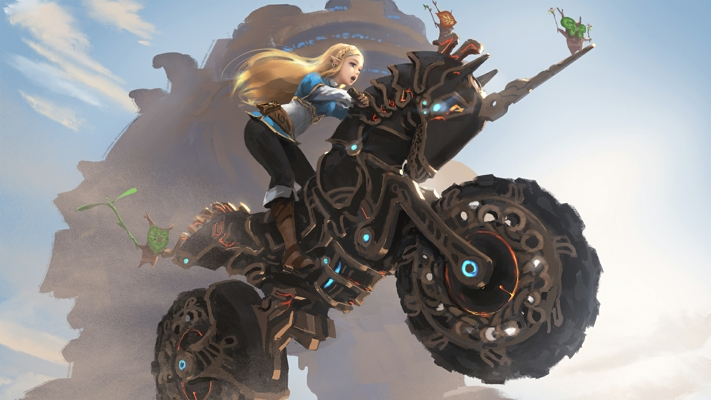

遮罩中心使用的播放图标：

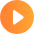

目标：正常显示图片；鼠标移入图片盒子后，显示覆盖整张图片的半透明黑色遮罩，中央出现播放图标；移开后遮罩消失。

原参考文件 `网页遮罩显示隐藏切换案例.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    * {
      margin: 0;
      padding: 0;
    }

    .box {
      width: 711px;
      height: 400px;
      border: 3px solid orange;
      margin: 100px auto;
      position: relative;
    }

    .mask {
      /* 默认隐藏 */
      display: none;

      /* 子绝父相 */
      position: absolute;
      top: 0;
      left: 0;

      width: 100%;
      height: 100%;
      background:rgba(0,0,0,.5) url('./images/arr.png') no-repeat center center;
    }

    /* 移入box之后，让mask盒子显示 */
    .box:hover .mask {
      display: block;
    }

  </style>
</head>
<body>
  <div class="box">
    <!-- 展示的图片 -->
    <img src="./images/sed.jpg" alt="">

    <!-- 半透明的遮罩层 -->
    <div class="mask"></div>
  </div>
</body>
</html>
```

思路拆解：

1. `.box` 相对定位，提供遮罩参照。
2. `.mask` 默认隐藏，绝对定位贴内容区域左上角。
3. 宽高100%覆盖内部图片区域；`rgba` 提供半透明背景。
4. 背景图片 `arr.png` 不重复且居中，用作播放图标。
5. `.box:hover .mask` 显示遮罩，触发条件放在一直可见的父盒子上。

**补充：** 原代码没有 `border-box`，711px × 400px是内容尺寸；加四周3px边框后，外部尺寸为717px × 406px。遮罩覆盖内部区域，不应把这两个尺寸混成一个。

播放图标使用背景图片，`rgba` 只让背景颜色半透明，图标不因此变淡。这个练习只有CSS显示效果，没有实现视频播放功能。目录还提供讲解视频，可配合原素材练习。


### 4.5 选做项目：尚合与腾讯云

本日选做仍提供尚合、腾讯云的设计图、图片素材、文字和说明，和第06天的项目练习衔接。它们**没有提供 HTML/CSS 源码**，应根据设计图完成布局，不能把下面的设计图称为已实现页面。

尚合设计图：

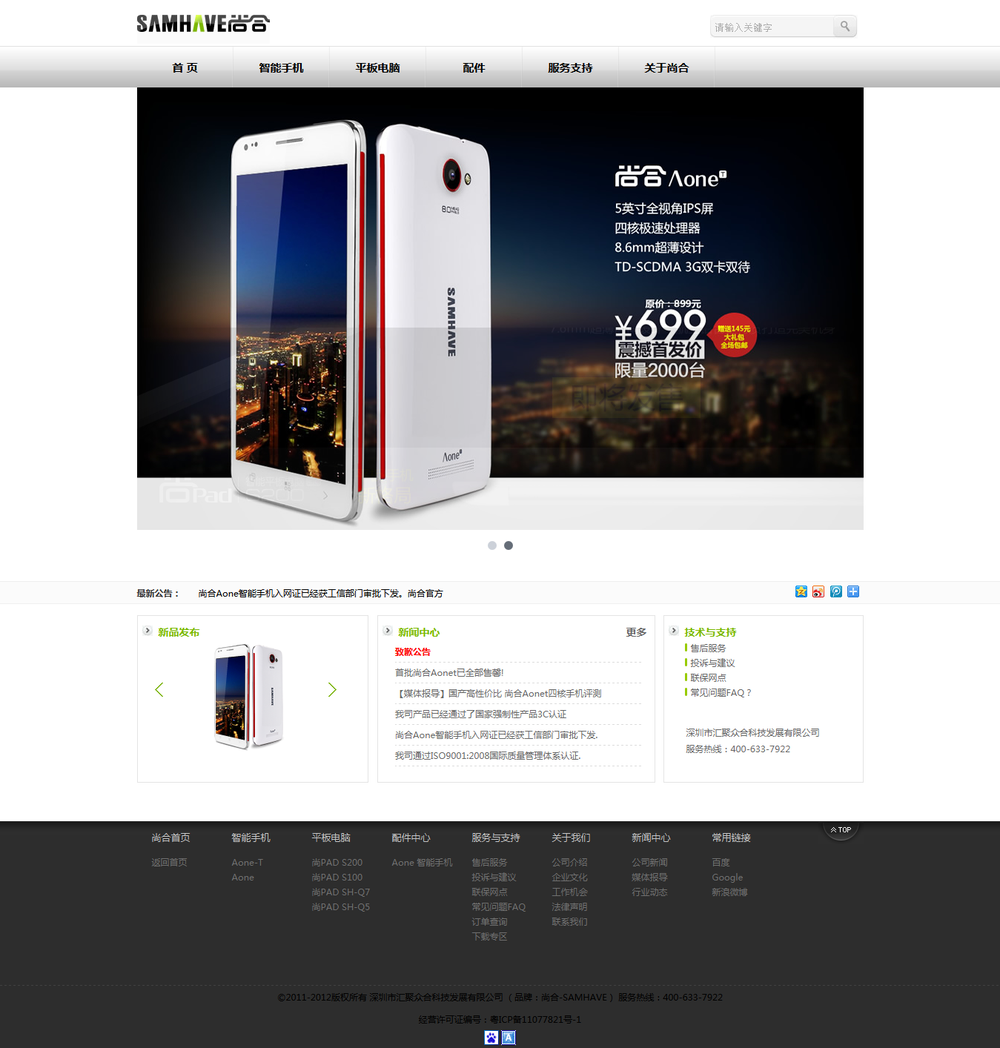

目录 `项目01-尚合项目★★★★★` 包含 `尚合.png`、`images`、`文字.txt`、`说明.txt`。按导航、主图、公告、三栏内容、页脚拆分；文字素材包括“尚合Aone智能手机”等公告和各栏目名称。先复用盒模型与浮动整理主体，再按图补需要的定位及装饰。

腾讯云设计图：

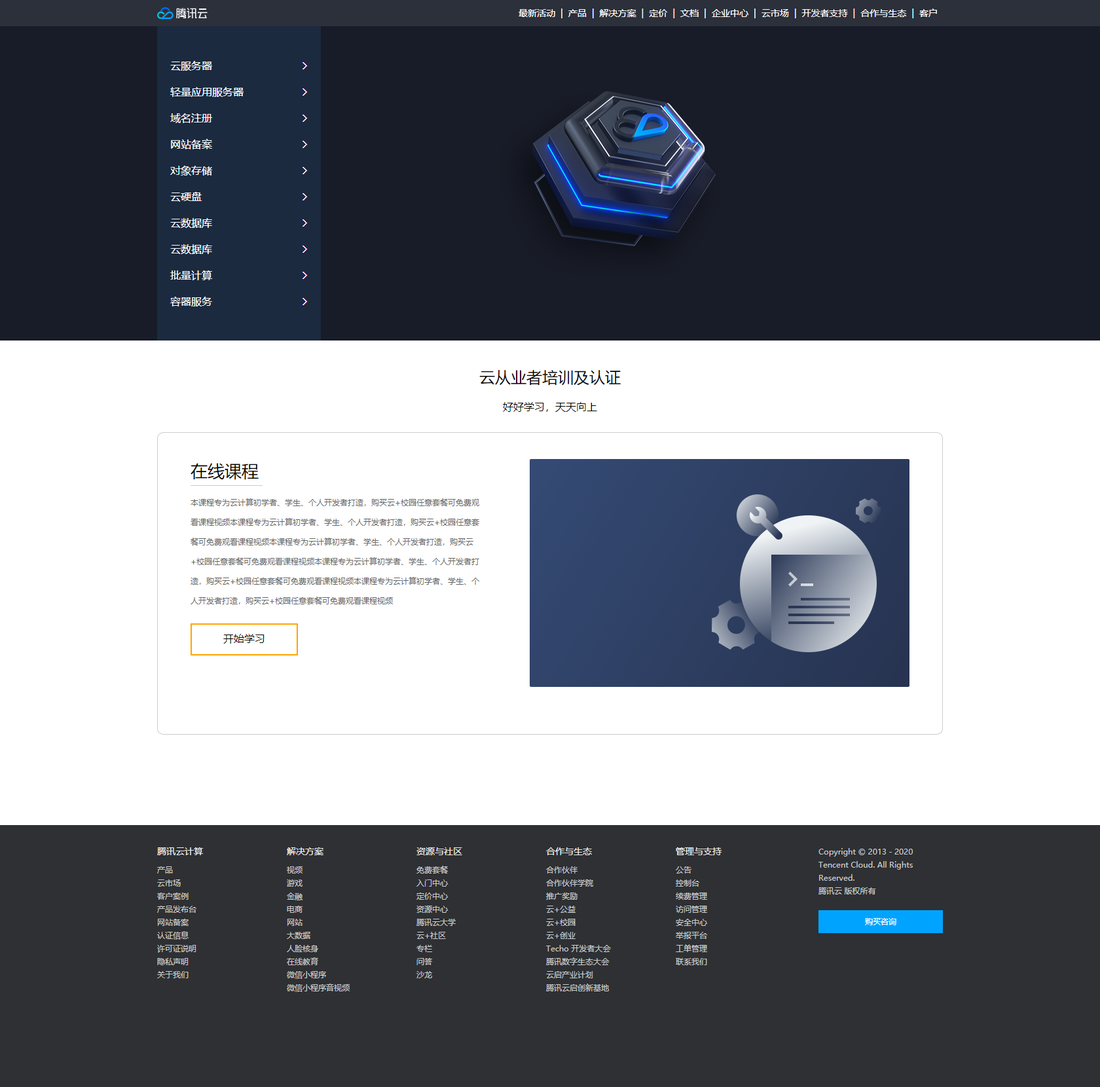

目录 `项目02-腾讯云项目★★★★★★` 包含 `设计图.png`、`images`、`文字.txt`、`说明.txt`。依次拆解通栏导航、主视觉、课程介绍与页脚；文字素材包含“云从业者培训及认证”“在线课程”等内容。以实际设计图为准处理图文排列和交互提示。

**补充：** 尚合说明正文复用了“腾讯云案例”的名称，两份说明还保留“后一天学习定位”的旧提示。它们是练习安排的复用文字，不改变本日已学习定位的事实；本日笔记不由这些旧提示延伸下一课内容。

原说明强调：跟着讲解练习后，再尝试只看设计图独立写出页面。可选一个项目巩固，不需要同时完成两个。


### 4.6 原课学习流程

根据 `04-作业/每日学习流程.txt` 整理：

1. 参考PDF梳理本日XMind，约10分钟；最好自己整理一次。
2. 观看课堂布置的了解性视频，约20分钟。
3. 课堂代码练习3～5遍，约20～30分钟，以不看参考能写出为目标。
4. 完成三项必做，约20～30分钟；不仅抄代码，还要复述实现思路。
5. 有余力时选1～2项选做，约20～30分钟；优先练习本日定位、遮罩及显示隐藏。

这些是原课建议时长，不是每个人必须遵守的耗时。本日内容先通过下面的检查，再安排后续学习。


### 4.7 本日复习检查

| 要回答的问题 | 应能说清的关键点 |
| --- | --- |
| relative、absolute、fixed分别参照谁？ | 自己原位置；最近定位祖先/初始包含块；本课普通页面可视区域 |
| 谁保留原来的标准流位置？ | relative保留；absolute与fixed脱标 |
| 子绝父相解决什么？ | 父保留主体布局，子参照父自由定位叠放 |
| 水平居中两个50%分别参照谁？ | left参照父区域宽度，translateX参照自身宽度 |
| 双向居中怎么写？ | left/top各50%，translate(-50%, -50%) |
| 本例如何提高粉色盒子层级？ | 定位后写z-index:1，在相同可比较环境中判断 |
| 图片底部缝隙从哪里来？ | 行内基线排版；可改垂直对齐或改为块级 |
| 正圆与胶囊有什么尺寸要求？ | 正圆是正方形加50%；胶囊为横向长方形加高度一半 |
| overflow:hidden和display:none有什么区别？ | 前者裁切超出内容，后者让整个元素不显示且不占布局位置 |
| visibility:hidden和display:none怎么区分？ | 普通流盒子隐藏后，前者保留位置，后者不保留 |
| opacity和rgba怎么选？ | 整体透明用opacity，只有背景色透明用rgba |
| 如何让父元素悬停时显示子元素？ | 默认子元素隐藏，父:hover 子设置显示 |
| 为什么链接伪类按LVHA排列？ | 相同权重且同时匹配时，后写样式影响覆盖 |
| :hover、:focus、属性选择器分别选什么？ | 悬停状态、焦点状态、HTML属性 |

不看完成代码，独立完成hot角标、二维码居中和二维码悬停显示，再说明每个定位参照和每条新增声明的作用。本日的核心是把主体布局与这些细节效果衔接起来。
